# Project 1 – Natural Language Inference (SNLI)

**Task:** given a *premise* and a *hypothesis*, predict whether the premise **entails**, **contradicts** or is **neutral** towards the hypothesis.

**What we compare:**

| | |
|---|---|
| **Representations** | R1 token indicators · R2 bag-of-words · R3 bag-of-words + cross-sentence features |
| **Architectures** | A1 log-linear · A2 MLP (tutorial) · A3 MLP with two hidden layers, tuned on validation data |
| **Evaluation** | 5-fold cross-validation, accuracy (+ per-class F1), Bayesian estimation with a ROPE |

Run the notebook from top to bottom (Kernel → Restart & Run All). Figures for the slides are saved in `results/graphs/`.

## 0. Setup

In [1]:
import os
import re
import sys
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

warnings.simplefilter("ignore")

# the course code (part1/) is in the same folder as this notebook
sys.path.insert(0, ".")
import part1

# the three labels, in the same order as SNLI uses them (0, 1, 2)
LABELS = part1.clslib.NamedClasses(["entailment", "neutral", "contradiction"])

SEED = 0
N_TRAIN = 50000   # size of our training sample
N_VAL = 2000      # size of our validation sample

os.makedirs("results/graphs", exist_ok=True)

## 1. Data

We use SNLI. Pairs with label −1 are removed: those are pairs where the annotators did not agree on a label.

To keep the experiments fast we take a random **sample of 50,000 training pairs** (out of ~550k). Every example is stored as `((premise, hypothesis), label)`.
- `train_pairs`: used for cross-validation
- `val_pairs`: 2,000 pairs from SNLI's validation split, only used to look at how the MLP trains and to choose A3 (section 6)
- `test_pairs`: SNLI's test split, used **once** at the very end

In [2]:
snli = load_dataset("stanfordnlp/snli")
print(snli)


def to_pairs(split):
    # turn a SNLI split into a list of ((premise, hypothesis), label)
    pairs = []
    for premise, hypothesis, label in zip(split["premise"], split["hypothesis"], split["label"]):
        if label != -1:   # -1 means the annotators did not agree, so we skip it
            pairs.append(((premise, hypothesis), label))
    return pairs


all_train = to_pairs(snli["train"])
all_val = to_pairs(snli["validation"])
test_pairs = to_pairs(snli["test"])

# take a random sample (with the same seed we get the same sample every time)
rng = np.random.default_rng(SEED)

train_order = rng.permutation(len(all_train))
train_pairs = []
for i in train_order[:N_TRAIN]:
    train_pairs.append(all_train[i])

val_order = rng.permutation(len(all_val))
val_pairs = []
for i in val_order[:N_VAL]:
    val_pairs.append(all_val[i])

print("train sample:", len(train_pairs), "| val sample:", len(val_pairs), "| test:", len(test_pairs))
print("example:", train_pairs[0])

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})
train sample: 50000 | val sample: 2000 | test: 9824
example: (('A man holding a video camera standing next to a woman by water.', 'The man is holding a microphone as he introduces the woman standing by the water.'), 2)


**Cleaning and class balance.** How many pairs did we remove (label −1), and are the classes balanced in every split? If one class were much bigger, a model could get a high accuracy by mostly predicting that class, so balanced classes make **accuracy** a fair metric.

,pairs,removed (-1),entailment,neutral,contradiction
split,,,,,
train (full),549367,785.0,0.334,0.333,0.333
train (our sample),50000,NaN,0.335,0.329,0.336
validation (full),9842,158.0,0.338,0.329,0.333
test,9824,176.0,0.343,0.328,0.329


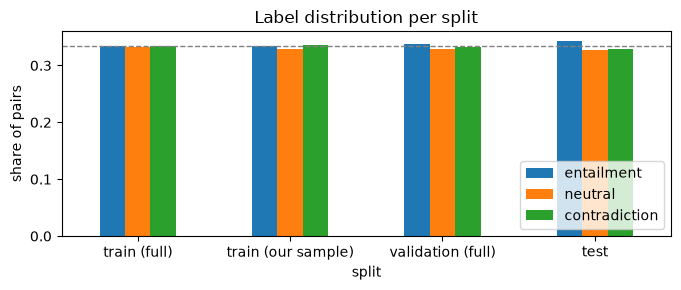

majority baseline: 0.336


In [3]:
def count_removed(split_name):
    removed = 0
    for label in snli[split_name]["label"]:
        if label == -1:
            removed += 1
    return removed


def label_shares(pairs):
    counts = Counter()
    for pair, label in pairs:
        counts[LABELS.name(label)] += 1
    shares = {}
    for name in LABELS:
        shares[name] = counts[name] / len(pairs)
    return shares


splits = [
    ("train (full)", all_train, count_removed("train")),
    ("train (our sample)", train_pairs, None),
    ("validation (full)", all_val, count_removed("validation")),
    ("test", test_pairs, count_removed("test")),
]

rows = []
for split_name, pairs, removed in splits:
    row = {"split": split_name, "pairs": len(pairs), "removed (-1)": removed}
    row.update(label_shares(pairs))
    rows.append(row)
data_table = pd.DataFrame(rows).set_index("split")
display(data_table.round(3))

# grouped bar chart: label shares per split
data_table[list(LABELS)].plot.bar(rot=0, figsize=(7, 3))
plt.axhline(1 / 3, color="grey", linestyle="--", linewidth=1)
plt.ylabel("share of pairs")
plt.title("Label distribution per split")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/graphs/label_distribution.png", dpi=150)
plt.show()

# majority baseline: the accuracy you get by always predicting the biggest class
majority = max(label_shares(train_pairs).values())
print("majority baseline:", round(majority, 3))

Some quick statistics that motivated the features in R3 (section 5): how long are premises and hypotheses, and how often does the hypothesis contain a negation, per label? (Computed on the training sample only.)

In [4]:
# a regular expression that finds negation words like "not", "no", "nobody", "isn't"
NEGATION = re.compile(r"\b(?:not|no|never|nobody|nothing|none|cannot)\b|n't", re.IGNORECASE)


def has_negation(sentence):
    if NEGATION.search(sentence):
        return True
    else:
        return False


rows = []
for (premise, hypothesis), label in train_pairs:
    rows.append({
        "label": LABELS.name(label),
        "premise words": len(premise.split()),
        "hypothesis words": len(hypothesis.split()),
        "negation in hypothesis": has_negation(hypothesis),
    })
stats = pd.DataFrame(rows)

# average per label
stats.groupby("label").mean().loc[list(LABELS)].round(3)

,premise words,hypothesis words,negation in hypothesis
label,,,
entailment,12.894,6.644,0.008
neutral,12.805,8.261,0.009
contradiction,12.846,7.353,0.049


## 2. Tokenizer

A BPE tokenizer trained with the course's `train_tokenizer` (`min_frequency=2`, as in the tutorial). Two questions:

1. **Which text to train it on?** We compare three sources on the same validation sentences: the tutorial's kind of data (AG News articles), our training sample, and all SNLI training text (a larger resource of the same kind; we only use the text, not the labels, and no validation/test data).
2. **Which vocabulary size?** 500, 1000, 2000 (and 4000 in section 4b).

We measure the **average number of tokens per sentence** (fewer = more words kept whole) and the **UNK rate**.

In [5]:
# text from our training sample
sample_corpus = []
for (premise, hypothesis), label in train_pairs:
    sample_corpus.append(premise)
    sample_corpus.append(hypothesis)

# all SNLI training text (every premise appears ~3 times, we keep it once)
full_corpus = []
seen_premises = set()
for premise in snli["train"]["premise"]:
    if premise not in seen_premises:
        seen_premises.add(premise)
        full_corpus.append(premise)
for hypothesis in snli["train"]["hypothesis"]:
    full_corpus.append(hypothesis)

# news articles, the kind of text the tutorial tokenizer was trained on
agnews_corpus = load_dataset("fancyzhx/ag_news")["train"]["text"]

print("sentences in our training sample:", len(sample_corpus))
print("sentences in all SNLI training text:", len(full_corpus))
print("texts in AG News:", len(agnews_corpus))

sentences in our training sample: 100000
sentences in all SNLI training text: 700888
texts in AG News: 120000


,trained on,vocab size,tokens per sentence,UNK rate
0,AG News (tutorial data),500,25.89,0.00003
1,AG News (tutorial data),1000,22.64,0.00003
2,AG News (tutorial data),2000,20.29,0.00004
3,our training sample,500,20.09,0.00000
4,our training sample,1000,16.39,0.00000
5,our training sample,2000,14.05,0.00000
6,all SNLI train text,500,20.28,0.00000
7,all SNLI train text,1000,16.50,0.00000
8,all SNLI train text,2000,14.08,0.00000


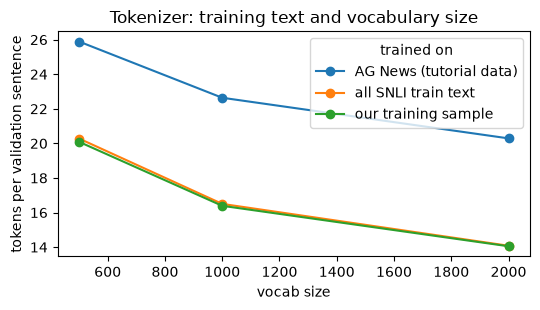

In [6]:
# validation sentences, which none of the tokenizers has seen
val_sentences = []
for (premise, hypothesis), label in val_pairs:
    val_sentences.append(premise)
    val_sentences.append(hypothesis)


def tokens_per_sentence(tok, sentences):
    unk_id = tok.token_to_id("[UNK]")
    total_tokens = 0
    unknown_tokens = 0
    for sentence in sentences:
        ids = tok.encode(sentence).ids
        total_tokens += len(ids)
        for i in ids:
            if i == unk_id:
                unknown_tokens += 1
    return total_tokens / len(sentences), unknown_tokens / total_tokens


rows = []
sources = [("AG News (tutorial data)", agnews_corpus), ("our training sample", sample_corpus), ("all SNLI train text", full_corpus)]
for source_name, training_text in sources:
    for vocab_size in [500, 1000, 2000]:
        tok = part1.experiment.train_tokenizer(training_text, vocab_size=vocab_size, min_frequency=2)
        tps, unk = tokens_per_sentence(tok, val_sentences)
        rows.append({"trained on": source_name, "vocab size": vocab_size,
                     "tokens per sentence": round(tps, 2), "UNK rate": round(unk, 5)})

tokenizer_comparison = pd.DataFrame(rows)
display(tokenizer_comparison)

pivot = tokenizer_comparison.pivot(index="vocab size", columns="trained on", values="tokens per sentence")
pivot.plot(marker="o", figsize=(5.5, 3.2))
plt.ylabel("tokens per validation sentence")
plt.title("Tokenizer: training text and vocabulary size")
plt.tight_layout()
plt.savefig("results/graphs/tokenizer_comparison.png", dpi=150)
plt.show()

**Our choice:** we train our tokenizers on **all SNLI training text** (it is free extra text of exactly the right kind and contains no validation/test data). The comparison above shows whether that matters compared to our sample, and that news text is a poor fit for SNLI captions. The main tokenizer uses **vocab size 1000**; the effect of the vocabulary size on accuracy is tested in section 4b.

In [7]:
tokenizer = part1.experiment.train_tokenizer(full_corpus, vocab_size=1000, min_frequency=2)

# look at one example
premise = train_pairs[0][0][0]
hypothesis = train_pairs[0][0][1]
print("premise:   ", tokenizer.encode(premise).tokens)
print("hypothesis:", tokenizer.encode(hypothesis).tokens)




premise:    ['▁A', '▁man', '▁holding', '▁a', '▁v', 'ide', 'o', '▁camera', '▁standing', '▁next', '▁to', '▁a', '▁woman', '▁by', '▁water.']
hypothesis: ['▁The', '▁man', '▁is', '▁holding', '▁a', '▁micro', 'ph', 'one', '▁as', '▁he', '▁in', 't', 'ro', 'd', 'u', 'c', 'es', '▁the', '▁woman', '▁standing', '▁by', '▁the', '▁water.']


## 3. Representations R1 and R2

The tutorial's encoders turn **one** text into a vector. NLI has **two** texts, and it matters which sentence a word is in ("not" in the hypothesis means something different from "not" in the premise). So we make a vector for the premise and a vector for the hypothesis **separately** and put them next to each other:

`[ premise vector (V numbers) | hypothesis vector (V numbers) ]` → 2V numbers, with V = 1000.

- **R1 – token indicators:** 1 if a token is in the sentence, 0 if not.
- **R2 – bag-of-words:** how many times each token is in the sentence.

The only difference in the code is `= 1` (R1) versus `+= 1` (R2).

In [8]:
class PairIndicator:
    # R1: for premise and hypothesis, 1 if a token is in the sentence, 0 if not

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] = 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] = 1

        # put them next to each other
        return np.concatenate([premise_vector, hypothesis_vector])


class PairBagOfWords:
    # R2: same as R1 but we count how many times each token occurs

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        return np.concatenate([premise_vector, hypothesis_vector])

In [9]:
R1 = PairIndicator(tokenizer)
R2 = PairBagOfWords(tokenizer)

# test on an example
x = ("A man is playing a guitar on a stage.", "A man is not playing music.")
print("dimensions:", len(R1), len(R2))
print("sum of R1:", R1(x).sum(), "| sum of R2:", R2(x).sum())   # R2 is bigger because "a" is counted twice

dimensions: 2000 2000
sum of R1: 16.0 | sum of R2: 17.0


## 4. Cross-validation with A1 and A2

We use the course's `cross_validation_split` (5 folds) and `cross_validation_experiment`. **Cross-validation:** the training sample is split into 5 parts; each model is trained on 4 parts and tested on the 5th, five times, so every system gets 5 accuracy measurements. All systems use **exactly the same folds**, so the comparisons are fair (paired).

The architectures are just settings for that function:
- **A1** – log-linear softmax regression (scikit-learn), as in the tutorial
- **A2** – one-hidden-layer MLP with the tutorial's settings

`run(name, encoder, architecture)` does the cross-validation for one system and stores the results in `my_classifiers`.

In [10]:
A1 = {
    "model_option": "logistic",
    "loglin_args": {"max_iter": 100},
    "smlp_args": {},
}

A2 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 10},
    "num_layers": 1,   # one hidden layer, like the tutorial
}

# The course code builds (and loads) its MLP with the class part1.smlp.SparseMLP, which has ONE hidden layer.
# For A3 we also want a version with TWO hidden layers (defined in section 6b). use_layers(n) tells the course
# code which of the two classes to use; for now it is always the original one.
OneLayerSparseMLP = part1.smlp.SparseMLP
MLP_CLASSES = {1: OneLayerSparseMLP}


def use_layers(num_layers):
    part1.smlp.SparseMLP = MLP_CLASSES[num_layers]


num_folds = 5
my_seeds = [0]

# make the folds once, so every system uses exactly the same folds
cv_sets = {}
for seed in my_seeds:
    cv_sets[seed] = part1.experiment.cross_validation_split(train_pairs, k=num_folds, seed=seed)

my_classifiers = {}


def run(name, encoder, architecture):
    # cross-validate one system and save the results under `name`
    my_classifiers[name] = []
    all_accuracies = []

    if architecture["model_option"] == "mlp":
        use_layers(architecture["num_layers"])   # one or two hidden layers

    for seed in my_seeds:
        result = part1.experiment.cross_validation_experiment(
            data_splits=cv_sets[seed],
            outcome_space=LABELS,
            encoder=encoder,
            model_option=architecture["model_option"],
            loglin_args=architecture["loglin_args"],
            smlp_args=architecture["smlp_args"],
            save_to="results/" + name + "/seed-" + str(seed),
        )
        my_classifiers[name].append(result)

        for accuracy in result["accuracies"].values():
            all_accuracies.append(accuracy)

    print(name, "mean accuracy:", round(np.mean(all_accuracies), 4), "(std", round(np.std(all_accuracies), 4), ")")

In [11]:
run("A1_R1", R1, A1)
run("A1_R2", R2, A1)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R1 mean accuracy: 0.5856 (std 0.007 )


  0%|          | 0/5 [00:00<?, ?it/s]

A1_R2 mean accuracy: 0.5848 (std 0.0069 )


In [12]:
run("A2_R1", R1, A2)
run("A2_R2", R2, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.830 seconds
Dataloader done! Time taken: 0.550 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0729 | train acc: 0.4452 | val loss: 1.0393 | val acc: 0.5124
Epoch 02 | train loss: 0.9905 | train acc: 0.5472 | val loss: 0.9707 | val acc: 0.5481
Epoch 03 | train loss: 0.9244 | train acc: 0.5834 | val loss: 0.9340 | val acc: 0.5632
Epoch 04 | train loss: 0.8863 | train acc: 0.5996 | val loss: 0.9157 | val acc: 0.5736
Epoch 05 | train loss: 0.8609 | train acc: 0.6165 | val loss: 0.9065 | val acc: 0.5786
Epoch 06 | train loss: 0.8427 | train acc: 0.6241 | val loss: 0.9020 | val acc: 0.5794
Epoch 07 | train loss: 0.8298 | train acc: 0.6301 | val loss: 0.8979 | val acc: 0.5817
Epoch 08 | train loss: 0.8179 | train acc: 0.6367 | val loss: 0.8958 | val acc: 0.5830
Epoch 09 | train loss: 0.8067 | train acc: 0.6442 | val loss: 0.8953 | val acc: 0.5875
Epoch 10 | train loss: 0.7962 | train acc: 0.6480 | val loss: 0.8940 | val acc: 0.5832
Training done! Time taken: 23.322 seconds
Transforming documents...
Document transformation done! Time taken: 1.912 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0738 | train acc: 0.4484 | val loss: 1.0397 | val acc: 0.5125
Epoch 02 | train loss: 0.9894 | train acc: 0.5505 | val loss: 0.9740 | val acc: 0.5426
Epoch 03 | train loss: 0.9223 | train acc: 0.5857 | val loss: 0.9417 | val acc: 0.5571
Epoch 04 | train loss: 0.8831 | train acc: 0.6044 | val loss: 0.9270 | val acc: 0.5614
Epoch 05 | train loss: 0.8580 | train acc: 0.6183 | val loss: 0.9191 | val acc: 0.5681
Epoch 06 | train loss: 0.8389 | train acc: 0.6265 | val loss: 0.9150 | val acc: 0.5712
Epoch 07 | train loss: 0.8245 | train acc: 0.6340 | val loss: 0.9126 | val acc: 0.5740
Epoch 08 | train loss: 0.8137 | train acc: 0.6385 | val loss: 0.9111 | val acc: 0.5734
Epoch 09 | train loss: 0.8017 | train acc: 0.6484 | val loss: 0.9096 | val acc: 0.5767
Epoch 10 | train loss: 0.7912 | train acc: 0.6526 | val loss: 0.9090 | val acc: 0.5740
Training done! Time taken: 22.464 seconds
Transforming documents...
Document transformation done! Time taken: 1.948 seconds
Datalo

... (14 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0723 | train acc: 0.4462 | val loss: 1.0377 | val acc: 0.5141
Epoch 02 | train loss: 0.9927 | train acc: 0.5413 | val loss: 0.9677 | val acc: 0.5532
Epoch 03 | train loss: 0.9306 | train acc: 0.5774 | val loss: 0.9301 | val acc: 0.5739
Epoch 04 | train loss: 0.8921 | train acc: 0.5988 | val loss: 0.9092 | val acc: 0.5860
Epoch 05 | train loss: 0.8668 | train acc: 0.6117 | val loss: 0.9008 | val acc: 0.5876
Epoch 06 | train loss: 0.8488 | train acc: 0.6199 | val loss: 0.8923 | val acc: 0.5884
Epoch 07 | train loss: 0.8357 | train acc: 0.6279 | val loss: 0.8884 | val acc: 0.5895
Epoch 08 | train loss: 0.8225 | train acc: 0.6345 | val loss: 0.8847 | val acc: 0.5931
Epoch 09 | train loss: 0.8119 | train acc: 0.6401 | val loss: 0.8832 | val acc: 0.5951
Epoch 10 | train loss: 0.8021 | train acc: 0.6458 | val loss: 0.8821 | val acc: 0.5970
Training done! Time taken: 21.349 seconds
Transforming documents...
Document transformation done! Time taken: 2.003 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0721 | train acc: 0.4417 | val loss: 1.0366 | val acc: 0.5099
Epoch 02 | train loss: 0.9909 | train acc: 0.5456 | val loss: 0.9724 | val acc: 0.5436
Epoch 03 | train loss: 0.9273 | train acc: 0.5814 | val loss: 0.9371 | val acc: 0.5653
Epoch 04 | train loss: 0.8885 | train acc: 0.6012 | val loss: 0.9186 | val acc: 0.5747
Epoch 05 | train loss: 0.8640 | train acc: 0.6136 | val loss: 0.9094 | val acc: 0.5787
Epoch 06 | train loss: 0.8454 | train acc: 0.6226 | val loss: 0.9035 | val acc: 0.5804
Epoch 07 | train loss: 0.8313 | train acc: 0.6309 | val loss: 0.8993 | val acc: 0.5820
Epoch 08 | train loss: 0.8188 | train acc: 0.6381 | val loss: 0.8969 | val acc: 0.5869
Epoch 09 | train loss: 0.8071 | train acc: 0.6443 | val loss: 0.8960 | val acc: 0.5864
Epoch 10 | train loss: 0.7973 | train acc: 0.6486 | val loss: 0.8938 | val acc: 0.5904
Training done! Time taken: 21.416 seconds
A2_R2 mean accuracy: 0.5892 (std 0.0064 )


### 4b. Does the vocabulary size matter for accuracy?

We cross-validate A2 with R2 for tokenizers with different vocabulary sizes, plus one trained on news text (like the tutorial's). We use the **CV accuracies** (not the test set, which we keep for the very end). These runs are kept in a separate dictionary, `vocab_results`, so they do not end up in the main comparison.

In [13]:
vocab_tokenizers = {
    "500": part1.experiment.train_tokenizer(full_corpus, vocab_size=500, min_frequency=2),
    "2000": part1.experiment.train_tokenizer(full_corpus, vocab_size=2000, min_frequency=2),
    "4000": part1.experiment.train_tokenizer(full_corpus, vocab_size=4000, min_frequency=2),
    "1000 (news text)": part1.experiment.train_tokenizer(agnews_corpus, vocab_size=1000, min_frequency=2),
}

vocab_results = {}
vocab_results["1000"] = my_classifiers["A2_R2"]   # already done in section 4
for vocab_name, tok in vocab_tokenizers.items():
    run("vocab_" + vocab_name, PairBagOfWords(tok), A2)
    vocab_results[vocab_name] = my_classifiers.pop("vocab_" + vocab_name)   # keep it out of the main comparison

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.017 seconds
Dataloader done! Time taken: 0.286 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0684 | train acc: 0.4441 | val loss: 1.0367 | val acc: 0.5003
Epoch 02 | train loss: 1.0017 | train acc: 0.5289 | val loss: 0.9838 | val acc: 0.5345
Epoch 03 | train loss: 0.9524 | train acc: 0.5588 | val loss: 0.9556 | val acc: 0.5524
Epoch 04 | train loss: 0.9235 | train acc: 0.5739 | val loss: 0.9406 | val acc: 0.5608
Epoch 05 | train loss: 0.9046 | train acc: 0.5851 | val loss: 0.9321 | val acc: 0.5662
Epoch 06 | train loss: 0.8908 | train acc: 0.5936 | val loss: 0.9271 | val acc: 0.5689
Epoch 07 | train loss: 0.8800 | train acc: 0.5996 | val loss: 0.9231 | val acc: 0.5729
Epoch 08 | train loss: 0.8681 | train acc: 0.6068 | val loss: 0.9204 | val acc: 0.5737
Epoch 09 | train loss: 0.8585 | train acc: 0.6132 | val loss: 0.9171 | val acc: 0.5770
Epoch 10 | train loss: 0.8498 | train acc: 0.6175 | val loss: 0.9142 | val acc: 0.5790
Training done! Time taken: 21.091 seconds
Transforming documents...
Document transformation done! Time taken: 1.971 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0742 | train acc: 0.4296 | val loss: 1.0435 | val acc: 0.4946
Epoch 02 | train loss: 1.0042 | train acc: 0.5262 | val loss: 0.9902 | val acc: 0.5308
Epoch 03 | train loss: 0.9537 | train acc: 0.5572 | val loss: 0.9633 | val acc: 0.5445
Epoch 04 | train loss: 0.9244 | train acc: 0.5766 | val loss: 0.9489 | val acc: 0.5503
Epoch 05 | train loss: 0.9052 | train acc: 0.5877 | val loss: 0.9414 | val acc: 0.5563
Epoch 06 | train loss: 0.8915 | train acc: 0.5947 | val loss: 0.9372 | val acc: 0.5548
Epoch 07 | train loss: 0.8798 | train acc: 0.6003 | val loss: 0.9335 | val acc: 0.5585
Epoch 08 | train loss: 0.8691 | train acc: 0.6082 | val loss: 0.9329 | val acc: 0.5599
Epoch 09 | train loss: 0.8604 | train acc: 0.6131 | val loss: 0.9282 | val acc: 0.5633
Epoch 10 | train loss: 0.8524 | train acc: 0.6183 | val loss: 0.9262 | val acc: 0.5639
Training done! Time taken: 21.167 seconds
Transforming documents...
Document transformation done! Time taken: 1.999 seconds
Datalo

... (38 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0723 | train acc: 0.4331 | val loss: 1.0334 | val acc: 0.4996
Epoch 02 | train loss: 0.9945 | train acc: 0.5299 | val loss: 0.9723 | val acc: 0.5398
Epoch 03 | train loss: 0.9471 | train acc: 0.5580 | val loss: 0.9451 | val acc: 0.5554
Epoch 04 | train loss: 0.9200 | train acc: 0.5744 | val loss: 0.9322 | val acc: 0.5651
Epoch 05 | train loss: 0.9019 | train acc: 0.5855 | val loss: 0.9229 | val acc: 0.5687
Epoch 06 | train loss: 0.8876 | train acc: 0.5937 | val loss: 0.9184 | val acc: 0.5724
Epoch 07 | train loss: 0.8754 | train acc: 0.6030 | val loss: 0.9100 | val acc: 0.5765
Epoch 08 | train loss: 0.8624 | train acc: 0.6091 | val loss: 0.9066 | val acc: 0.5780
Epoch 09 | train loss: 0.8519 | train acc: 0.6193 | val loss: 0.9015 | val acc: 0.5848
Epoch 10 | train loss: 0.8398 | train acc: 0.6253 | val loss: 0.8980 | val acc: 0.5843
Training done! Time taken: 24.225 seconds
Transforming documents...
Document transformation done! Time taken: 2.228 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0715 | train acc: 0.4398 | val loss: 1.0341 | val acc: 0.5040
Epoch 02 | train loss: 0.9955 | train acc: 0.5323 | val loss: 0.9762 | val acc: 0.5324
Epoch 03 | train loss: 0.9454 | train acc: 0.5589 | val loss: 0.9513 | val acc: 0.5488
Epoch 04 | train loss: 0.9204 | train acc: 0.5734 | val loss: 0.9404 | val acc: 0.5551
Epoch 05 | train loss: 0.9016 | train acc: 0.5870 | val loss: 0.9320 | val acc: 0.5619
Epoch 06 | train loss: 0.8869 | train acc: 0.5954 | val loss: 0.9280 | val acc: 0.5661
Epoch 07 | train loss: 0.8747 | train acc: 0.6030 | val loss: 0.9226 | val acc: 0.5696
Epoch 08 | train loss: 0.8634 | train acc: 0.6099 | val loss: 0.9190 | val acc: 0.5735
Epoch 09 | train loss: 0.8517 | train acc: 0.6179 | val loss: 0.9166 | val acc: 0.5736
Epoch 10 | train loss: 0.8405 | train acc: 0.6256 | val loss: 0.9120 | val acc: 0.5788
Training done! Time taken: 25.911 seconds
vocab_1000 (news text) mean accuracy: 0.5787 (std 0.0039 )


,vocab,mean CV accuracy,std
0,500,0.5759,0.0066
1,1000,0.5892,0.0064
2,2000,0.5929,0.0072
3,4000,0.5896,0.0063
4,1000 (news text),0.5787,0.0039


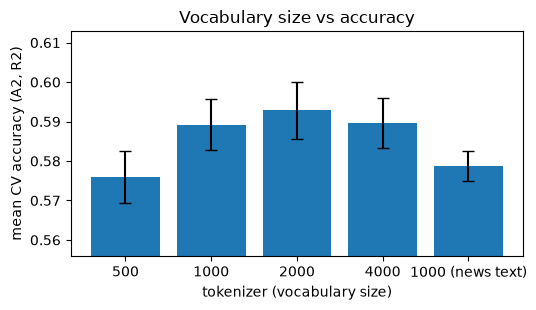

1000 vs 2000 (ROPE 0.01): P(1000 better) 0.009 | P(equivalent) 0.916 | P(2000 better) 0.074


In [14]:
def accuracies_of(results):
    # all fold accuracies of one system, as one array
    accuracies = []
    for result in results:
        for accuracy in result["accuracies"].values():
            accuracies.append(accuracy)
    return np.array(accuracies)


order = ["500", "1000", "2000", "4000", "1000 (news text)"]
means = []
stds = []
for vocab_name in order:
    means.append(accuracies_of(vocab_results[vocab_name]).mean())
    stds.append(accuracies_of(vocab_results[vocab_name]).std())

display(pd.DataFrame({"vocab": order, "mean CV accuracy": means, "std": stds}).round(4))

plt.figure(figsize=(5.5, 3.2))
plt.bar(order, means, yerr=stds, capsize=4)
plt.ylim(min(means) - 0.02, max(means) + 0.02)
plt.xlabel("tokenizer (vocabulary size)")
plt.ylabel("mean CV accuracy (A2, R2)")
plt.title("Vocabulary size vs accuracy")
plt.tight_layout()
plt.savefig("results/graphs/vocab_vs_accuracy.png", dpi=150)
plt.show()

# is 2000 practically better than 1000? (Bayesian estimation, explained in section 7)
posterior = part1.analysis.BenavoliCorrelatedT(accuracies_of(vocab_results["1000"]), accuracies_of(vocab_results["2000"]),
                                               runs=len(my_seeds), names=["vocab 1000", "vocab 2000"])
p_a, p_tie, p_b = posterior.probs(0.01)
print("1000 vs 2000 (ROPE 0.01): P(1000 better)", round(p_a, 3), "| P(equivalent)", round(p_tie, 3), "| P(2000 better)", round(p_b, 3))

## 5. Representation R3: cross-sentence features

R1 and R2 describe each sentence on its own. But NLI is about **how the two sentences relate**, and a log-linear model cannot work that out from two separate halves of a vector. R3 adds features that describe the relation directly:

| Feature | Idea |
|---|---|
| **new tokens in H** (V numbers) | tokens in the hypothesis that are not in the premise → new information suggests *neutral* |
| **overlap** | share of hypothesis tokens that also occur in the premise → high overlap suggests *entailment* |
| **length difference** | (len H − len P) / (len H + len P) |
| **negation** | hypothesis has a negation word and the premise does not → suggests *contradiction* |

R3 = R2 + these features → 3V + 3 numbers. All extra features are between −1 and 1, on the same scale as the other features.

In [15]:
class PairCrossFeatures:
    # R3: R2 + features that compare the premise and the hypothesis

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part + new-tokens part + 3 extra numbers
        return self.vocab_size * 3 + 3

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        # part 1 and 2: bag-of-words, the same as R2
        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        # part 3: tokens that are in the hypothesis but NOT in the premise
        new_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            if i not in premise_ids:
                new_vector[i] = 1

        # overlap: which part of the hypothesis tokens also appears in the premise
        if len(hypothesis_ids) > 0:
            in_premise = 0
            for i in hypothesis_ids:
                if i in premise_ids:
                    in_premise += 1
            overlap = in_premise / len(hypothesis_ids)
        else:
            overlap = 0

        # length difference, scaled to be between -1 and 1
        total_length = len(hypothesis_ids) + len(premise_ids)
        if total_length > 0:
            length_difference = (len(hypothesis_ids) - len(premise_ids)) / total_length
        else:
            length_difference = 0

        # negation: 1 if the hypothesis has a negation word and the premise doesn't
        if has_negation(hypothesis) and not has_negation(premise):
            negation = 1
        else:
            negation = 0

        extra = np.array([overlap, length_difference, negation])
        return np.concatenate([premise_vector, hypothesis_vector, new_vector, extra])


R3 = PairCrossFeatures(tokenizer)
print("dimensions:", len(R3))
print("overlap, length difference, negation for the example:", R3(x)[-3:])

dimensions: 3003
overlap, length difference, negation for the example: [ 0.57142857 -0.17647059  1.        ]


### 5b. Do the cross-sentence features differ between the labels?

Before training with R3, we check on the **training sample** whether each cross-sentence feature actually behaves differently for entailment, neutral and contradiction. We compute every feature exactly as R3 does (with the R3 encoder) and take the average per label. If a feature has about the same average for all three labels, it cannot help the classifier much.

label,entailment,neutral,contradiction
avg overlap (0-1),0.525,0.368,0.331
avg nr of new tokens in H,4.306,7.945,7.211
avg length difference (-1 to 1),-0.329,-0.188,-0.259
share with negation flag,0.008,0.008,0.049


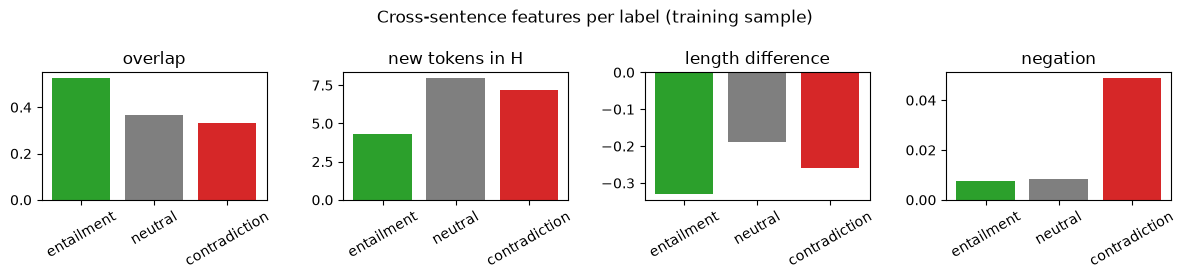

In [16]:
V = R3.vocab_size
rows = []
for pair, label in train_pairs:
    vector = R3(pair)
    rows.append({
        "label": LABELS.name(label),
        "overlap": vector[-3],
        "new tokens in H": vector[2 * V: 3 * V].sum(),   # how many different tokens are in H but not in P
        "length difference": vector[-2],
        "negation": vector[-1],
    })
feature_stats = pd.DataFrame(rows)

# rows = features, columns = labels (average per label)
feature_table = feature_stats.groupby("label").mean().loc[list(LABELS)].T
feature_table.index = ["avg overlap (0-1)", "avg nr of new tokens in H", "avg length difference (-1 to 1)", "share with negation flag"]
display(feature_table.round(3))

# one small bar chart per feature, for the slides
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for ax, feature in zip(axes, ["overlap", "new tokens in H", "length difference", "negation"]):
    averages = feature_stats.groupby("label")[feature].mean().loc[list(LABELS)]
    ax.bar(list(LABELS), averages, color=["tab:green", "tab:gray", "tab:red"])
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Cross-sentence features per label (training sample)")
plt.tight_layout()
plt.savefig("results/graphs/r3_features_per_label.png", dpi=150)
plt.show()

In [17]:
run("A1_R3", R3, A1)
run("A2_R3", R3, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R3 mean accuracy: 0.6635 (std 0.0044 )


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.404 seconds
Dataloader done! Time taken: 0.917 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0252 | train acc: 0.5111 | val loss: 0.9348 | val acc: 0.6007
Epoch 02 | train loss: 0.8625 | train acc: 0.6314 | val loss: 0.8351 | val acc: 0.6397
Epoch 03 | train loss: 0.7856 | train acc: 0.6664 | val loss: 0.8002 | val acc: 0.6537
Epoch 04 | train loss: 0.7477 | train acc: 0.6817 | val loss: 0.7860 | val acc: 0.6607
Epoch 05 | train loss: 0.7248 | train acc: 0.6935 | val loss: 0.7787 | val acc: 0.6676
Epoch 06 | train loss: 0.7088 | train acc: 0.7003 | val loss: 0.7742 | val acc: 0.6679
Epoch 07 | train loss: 0.6956 | train acc: 0.7062 | val loss: 0.7720 | val acc: 0.6692
Epoch 08 | train loss: 0.6835 | train acc: 0.7094 | val loss: 0.7700 | val acc: 0.6692
Epoch 09 | train loss: 0.6727 | train acc: 0.7160 | val loss: 0.7688 | val acc: 0.6703
Epoch 10 | train loss: 0.6618 | train acc: 0.7212 | val loss: 0.7682 | val acc: 0.6707
Training done! Time taken: 25.199 seconds
Transforming documents...
Document transformation done! Time taken: 2.488 seconds
Datalo

... (4 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0270 | train acc: 0.5206 | val loss: 0.9335 | val acc: 0.6042
Epoch 02 | train loss: 0.8655 | train acc: 0.6301 | val loss: 0.8267 | val acc: 0.6452
Epoch 03 | train loss: 0.7871 | train acc: 0.6650 | val loss: 0.7891 | val acc: 0.6623
Epoch 04 | train loss: 0.7500 | train acc: 0.6799 | val loss: 0.7747 | val acc: 0.6687
Epoch 05 | train loss: 0.7263 | train acc: 0.6938 | val loss: 0.7668 | val acc: 0.6698
Epoch 06 | train loss: 0.7092 | train acc: 0.6991 | val loss: 0.7618 | val acc: 0.6750
Epoch 07 | train loss: 0.6952 | train acc: 0.7052 | val loss: 0.7593 | val acc: 0.6746
Epoch 08 | train loss: 0.6834 | train acc: 0.7097 | val loss: 0.7587 | val acc: 0.6766
Epoch 09 | train loss: 0.6727 | train acc: 0.7163 | val loss: 0.7561 | val acc: 0.6763
Epoch 10 | train loss: 0.6609 | train acc: 0.7219 | val loss: 0.7564 | val acc: 0.6768
Training done! Time taken: 26.458 seconds
Transforming documents...
Document transformation done! Time taken: 2.526 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0220 | train acc: 0.5273 | val loss: 0.9318 | val acc: 0.5990
Epoch 02 | train loss: 0.8603 | train acc: 0.6338 | val loss: 0.8336 | val acc: 0.6382
Epoch 03 | train loss: 0.7846 | train acc: 0.6648 | val loss: 0.8000 | val acc: 0.6477
Epoch 04 | train loss: 0.7469 | train acc: 0.6836 | val loss: 0.7866 | val acc: 0.6539
Epoch 05 | train loss: 0.7248 | train acc: 0.6920 | val loss: 0.7794 | val acc: 0.6568
Epoch 06 | train loss: 0.7068 | train acc: 0.7006 | val loss: 0.7744 | val acc: 0.6602
Epoch 07 | train loss: 0.6928 | train acc: 0.7081 | val loss: 0.7720 | val acc: 0.6637
Epoch 08 | train loss: 0.6807 | train acc: 0.7141 | val loss: 0.7711 | val acc: 0.6640
Epoch 09 | train loss: 0.6685 | train acc: 0.7198 | val loss: 0.7701 | val acc: 0.6649
Epoch 10 | train loss: 0.6585 | train acc: 0.7240 | val loss: 0.7697 | val acc: 0.6664
Training done! Time taken: 26.796 seconds
A2_R3 mean accuracy: 0.6678 (std 0.0061 )


## 6. Overfitting and choosing A3

To choose a sensible third architecture, we first look at **whether A1 and A2 overfit**: we train each once on the training sample and compare accuracy on the training data with accuracy on the separate `val_pairs`. We use **R3**, the representation that works best.

- Training accuracy much higher than validation accuracy → the model memorises the training data (**overfitting**) → we need more regularisation.
- Both low → **underfitting** → we need a bigger model.

All decisions in this section are made on `val_pairs`, **not** on the cross-validation folds (those are used for the final comparison) and not on the test set.

In [18]:
val_texts = []
val_gold = []
for pair, label in val_pairs:
    val_texts.append(pair)
    val_gold.append(label)

train_texts = []
train_gold = []
for pair, label in train_pairs:
    train_texts.append(pair)
    train_gold.append(label)

# A1: train once, compare train and validation accuracy
model_a1 = part1.loglin.fit(train_pairs, R3, max_iter=100)
a1_train_acc = accuracy_score(train_gold, part1.loglin.predict(train_texts, model_a1, R3))
a1_val_acc = accuracy_score(val_gold, part1.loglin.predict(val_texts, model_a1, R3))
print("A1 (R3): train", round(a1_train_acc, 3), "| validation", round(a1_val_acc, 3), "| gap", round(a1_train_acc - a1_val_acc, 3))

A1 (R3): train 0.722 | validation 0.688 | gap 0.034


Transforming documents...
Document transformation done! Time taken: 2.548 seconds
Dataloader done! Time taken: 0.804 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0085 | train acc: 0.5345 | val loss: 0.8792 | val acc: 0.6240
Epoch 02 | train loss: 0.8366 | train acc: 0.6414 | val loss: 0.7817 | val acc: 0.6705
Epoch 03 | train loss: 0.7699 | train acc: 0.6709 | val loss: 0.7527 | val acc: 0.6860
Epoch 04 | train loss: 0.7395 | train acc: 0.6861 | val loss: 0.7422 | val acc: 0.6840
Epoch 05 | train loss: 0.7192 | train acc: 0.6951 | val loss: 0.7329 | val acc: 0.6905
Epoch 06 | train loss: 0.7036 | train acc: 0.7020 | val loss: 0.7293 | val acc: 0.6930
Epoch 07 | train loss: 0.6917 | train acc: 0.7076 | val loss: 0.7241 | val acc: 0.6945
Epoch 08 | train loss: 0.6794 | train acc: 0.7129 | val loss: 0.7236 | val acc: 0.6925
Epoch 09 | train loss: 0.6682 | train acc: 0.7181 | val loss: 0.7236 | val acc: 0.6980
Epoch 10 | train loss: 0.6565 | train acc: 0.7252 | val loss: 0.7223 | val acc: 0.6900
Training done! Time taken: 29.192 seconds


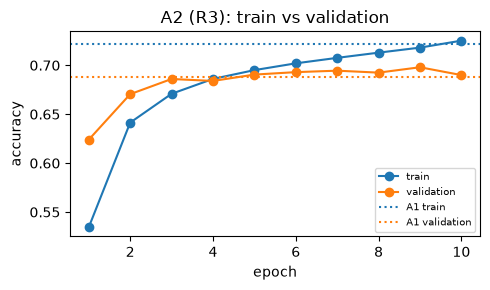

A2 (R3) last epoch: train 0.725 | validation 0.69 | gap 0.035


In [19]:
def training_curve(settings, encoder, num_layers):
    # train an MLP once on train_pairs and return train and validation accuracy per epoch,
    # plus the epoch the course code keeps (the one with the lowest validation loss)
    use_layers(num_layers)
    metrics, best_epoch, predictions = part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), encoder, save_to="results/curve",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    train_accuracy = []
    val_accuracy = []
    for epoch in metrics:
        train_accuracy.append(epoch["train_metrics"]["accuracy"])
        val_accuracy.append(epoch["val_metrics"]["accuracy"])
    return train_accuracy, val_accuracy, best_epoch


train_acc, val_acc, best_epoch = training_curve(A2["smlp_args"], R3, A2["num_layers"])

epochs = range(1, len(train_acc) + 1)
plt.figure(figsize=(5, 3))
plt.plot(epochs, train_acc, marker="o", label="train")
plt.plot(epochs, val_acc, marker="o", label="validation")
plt.axhline(a1_train_acc, color="tab:blue", linestyle=":", label="A1 train")
plt.axhline(a1_val_acc, color="tab:orange", linestyle=":", label="A1 validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("A2 (R3): train vs validation")
plt.legend(fontsize=7)
plt.tight_layout()
plt.savefig("results/graphs/overfitting_a1_a2.png", dpi=150)
plt.show()

print("A2 (R3) last epoch: train", round(train_acc[-1], 3), "| validation", round(val_acc[-1], 3),
      "| gap", round(train_acc[-1] - val_acc[-1], 3))

### 6b. A3: a deeper MLP, tuned against overfitting

For A3 we **add a second hidden layer**: a deeper network can combine features in more complex ways (e.g. a word in the premise *and* a word in the hypothesis *and* low overlap). But A2 already overfits, and an extra layer adds even more weights. So we tune A3's **regularisation** on `val_pairs`, one thing at a time:

1. **Dropout rate** (0.1, 0.3, 0.5, 0.7), with two hidden layers of 128 → keep the best.
2. **Hidden layer size** (16, 32, 64, 128, 256; both layers the same size) → keep the best.
3. **Weight decay** (1e-4, 1e-3, 1e-2), which shrinks the weights towards 0 at every step → keep the best.
4. **Check: 2 vs 1 hidden layer** with these best settings. If one layer does at least as well, the extra layer is not worth it and A3 uses one layer.

For every setting we record the **validation accuracy at the epoch the course code would keep** (lowest validation loss) and the **gap** between train and validation accuracy at that epoch. We pick the setting with the highest validation accuracy; the gap shows how much it overfits. All runs use 15 epochs; the learning rate and batch size stay as in A2.

In [20]:
import torch


class TwoLayerSparseMLP(torch.nn.Module):
    # the course's SparseMLP with one extra hidden layer:
    # sparse input -> hidden layer 1 -> ReLU -> dropout -> hidden layer 2 -> ReLU -> dropout -> output

    def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.2):
        super().__init__()
        # first layer: same as in the course code (the input is sparse)
        self.weight = torch.nn.Parameter(torch.empty(input_dim, hidden_dim))
        self.bias = torch.nn.Parameter(torch.zeros(hidden_dim))
        torch.nn.init.xavier_uniform_(self.weight)

        self.activation = torch.nn.ReLU()
        self.dropout = torch.nn.Dropout(dropout)

        # the extra hidden layer (same size as the first one)
        self.hidden2 = torch.nn.Linear(hidden_dim, hidden_dim)

        # output layer: same as in the course code
        self.output = torch.nn.Sequential(
            torch.nn.Linear(hidden_dim, num_classes),
            torch.nn.LogSoftmax(dim=-1),
        )

    def forward(self, x):
        x = torch.sparse.mm(x, self.weight) + self.bias
        x = self.dropout(self.activation(x))
        x = self.hidden2(x)
        x = self.dropout(self.activation(x))
        return self.output(x)


MLP_CLASSES[2] = TwoLayerSparseMLP

# quick check that it works on one sparse batch
from scipy.sparse import csr_matrix
check = TwoLayerSparseMLP(input_dim=len(R3), hidden_dim=8, num_classes=3)
print("output shape:", check(part1.smlp.scipy_to_torch_sparse(csr_matrix([R3(x)]))).shape)

output shape: torch.Size([1, 3])


In [21]:
def try_setting(num_layers, changes):
    # start from the A2 settings, apply the changes, train once and return the results
    settings = dict(A2["smlp_args"])
    settings["num_epochs"] = 15
    for key, value in changes.items():
        settings[key] = value
    train_accuracy, val_accuracy, best = training_curve(settings, R3, num_layers)
    return {"val acc": val_accuracy[best], "gap": train_accuracy[best] - val_accuracy[best], "epoch kept": best + 1}


tuning_rows = []

# step 1: dropout (two hidden layers)
for dropout in [0.1, 0.3, 0.5, 0.7]:
    result = try_setting(2, {"dropout": dropout})
    result.update({"step": "dropout", "value": dropout})
    tuning_rows.append(result)
    print("dropout", dropout, "->", result)
step1 = pd.DataFrame([r for r in tuning_rows if r["step"] == "dropout"])
best_dropout = step1.loc[step1["val acc"].idxmax(), "value"]
print("best dropout:", best_dropout)

Transforming documents...
Document transformation done! Time taken: 2.535 seconds
Dataloader done! Time taken: 0.824 seconds
Training...


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.9855 | train acc: 0.5202 | val loss: 0.8035 | val acc: 0.6495
Epoch 02 | train loss: 0.7836 | train acc: 0.6612 | val loss: 0.7503 | val acc: 0.6845
Epoch 03 | train loss: 0.7310 | train acc: 0.6886 | val loss: 0.7313 | val acc: 0.6845
Epoch 04 | train loss: 0.6994 | train acc: 0.7042 | val loss: 0.7257 | val acc: 0.6915
Epoch 05 | train loss: 0.6725 | train acc: 0.7177 | val loss: 0.7209 | val acc: 0.6915
Epoch 06 | train loss: 0.6456 | train acc: 0.7314 | val loss: 0.7242 | val acc: 0.6885
Epoch 07 | train loss: 0.6179 | train acc: 0.7458 | val loss: 0.7257 | val acc: 0.6915
Epoch 08 | train loss: 0.5852 | train acc: 0.7639 | val loss: 0.7296 | val acc: 0.6910
Epoch 09 | train loss: 0.5512 | train acc: 0.7797 | val loss: 0.7388 | val acc: 0.6875
Epoch 10 | train loss: 0.5148 | train acc: 0.8004 | val loss: 0.7531 | val acc: 0.6865
Epoch 11 | train loss: 0.4763 | train acc: 0.8184 | val loss: 0.7706 | val acc: 0.6930
Epoch 12 | train loss: 0.4359 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0173 | train acc: 0.4938 | val loss: 0.8559 | val acc: 0.6270
Epoch 02 | train loss: 0.8295 | train acc: 0.6364 | val loss: 0.7602 | val acc: 0.6715
Epoch 03 | train loss: 0.7630 | train acc: 0.6727 | val loss: 0.7350 | val acc: 0.6940
Epoch 04 | train loss: 0.7287 | train acc: 0.6907 | val loss: 0.7272 | val acc: 0.6885
Epoch 05 | train loss: 0.6988 | train acc: 0.7035 | val loss: 0.7218 | val acc: 0.6950
Epoch 06 | train loss: 0.6731 | train acc: 0.7190 | val loss: 0.7166 | val acc: 0.6885
Epoch 07 | train loss: 0.6472 | train acc: 0.7314 | val loss: 0.7144 | val acc: 0.6975
Epoch 08 | train loss: 0.6206 | train acc: 0.7449 | val loss: 0.7158 | val acc: 0.6945
Epoch 09 | train loss: 0.5950 | train acc: 0.7585 | val loss: 0.7195 | val acc: 0.6930
Epoch 10 | train loss: 0.5659 | train acc: 0.7731 | val loss: 0.7222 | val acc: 0.6890
Epoch 11 | train loss: 0.5381 | train acc: 0.7872 | val loss: 0.7278 | val acc: 0.6905
Epoch 12 | train loss: 0.5053 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0569 | train acc: 0.4353 | val loss: 0.9357 | val acc: 0.5925
Epoch 02 | train loss: 0.9081 | train acc: 0.5868 | val loss: 0.7934 | val acc: 0.6620
Epoch 03 | train loss: 0.8207 | train acc: 0.6413 | val loss: 0.7502 | val acc: 0.6775
Epoch 04 | train loss: 0.7773 | train acc: 0.6651 | val loss: 0.7330 | val acc: 0.6875
Epoch 05 | train loss: 0.7449 | train acc: 0.6850 | val loss: 0.7237 | val acc: 0.6945
Epoch 06 | train loss: 0.7219 | train acc: 0.6950 | val loss: 0.7174 | val acc: 0.6945
Epoch 07 | train loss: 0.7001 | train acc: 0.7070 | val loss: 0.7091 | val acc: 0.6935
Epoch 08 | train loss: 0.6792 | train acc: 0.7179 | val loss: 0.7081 | val acc: 0.6975
Epoch 09 | train loss: 0.6611 | train acc: 0.7269 | val loss: 0.7060 | val acc: 0.6955
Epoch 10 | train loss: 0.6418 | train acc: 0.7378 | val loss: 0.7050 | val acc: 0.6950
Epoch 11 | train loss: 0.6213 | train acc: 0.7499 | val loss: 0.7076 | val acc: 0.6960
Epoch 12 | train loss: 0.6035 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0937 | train acc: 0.3609 | val loss: 1.0708 | val acc: 0.5205
Epoch 02 | train loss: 1.0392 | train acc: 0.4702 | val loss: 0.9471 | val acc: 0.5855
Epoch 03 | train loss: 0.9547 | train acc: 0.5494 | val loss: 0.8521 | val acc: 0.6290
Epoch 04 | train loss: 0.8886 | train acc: 0.6033 | val loss: 0.7986 | val acc: 0.6580
Epoch 05 | train loss: 0.8493 | train acc: 0.6264 | val loss: 0.7703 | val acc: 0.6680
Epoch 06 | train loss: 0.8148 | train acc: 0.6458 | val loss: 0.7533 | val acc: 0.6845
Epoch 07 | train loss: 0.7917 | train acc: 0.6611 | val loss: 0.7421 | val acc: 0.6890
Epoch 08 | train loss: 0.7725 | train acc: 0.6740 | val loss: 0.7338 | val acc: 0.6915
Epoch 09 | train loss: 0.7558 | train acc: 0.6810 | val loss: 0.7290 | val acc: 0.6950
Epoch 10 | train loss: 0.7403 | train acc: 0.6897 | val loss: 0.7238 | val acc: 0.6975
Epoch 11 | train loss: 0.7244 | train acc: 0.6968 | val loss: 0.7196 | val acc: 0.6990
Epoch 12 | train loss: 0.7123 | train acc: 

In [22]:
# step 2: hidden layer size (two hidden layers, best dropout)
for hidden in [16, 32, 64, 128, 256]:
    result = try_setting(2, {"dropout": best_dropout, "hidden_dim": hidden})
    result.update({"step": "hidden size", "value": hidden})
    tuning_rows.append(result)
    print("hidden", hidden, "->", result)
step2 = pd.DataFrame([r for r in tuning_rows if r["step"] == "hidden size"])
best_hidden = int(step2.loc[step2["val acc"].idxmax(), "value"])
print("best hidden size:", best_hidden)

Transforming documents...
Document transformation done! Time taken: 2.467 seconds
Dataloader done! Time taken: 0.828 seconds
Training...


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1090 | train acc: 0.3415 | val loss: 1.0946 | val acc: 0.3450
Epoch 02 | train loss: 1.0841 | train acc: 0.3768 | val loss: 1.0513 | val acc: 0.4685
Epoch 03 | train loss: 1.0467 | train acc: 0.4593 | val loss: 0.9918 | val acc: 0.6095
Epoch 04 | train loss: 1.0017 | train acc: 0.5149 | val loss: 0.9250 | val acc: 0.6350
Epoch 05 | train loss: 0.9545 | train acc: 0.5582 | val loss: 0.8727 | val acc: 0.6515
Epoch 06 | train loss: 0.9250 | train acc: 0.5797 | val loss: 0.8427 | val acc: 0.6575
Epoch 07 | train loss: 0.8996 | train acc: 0.6010 | val loss: 0.8171 | val acc: 0.6720
Epoch 08 | train loss: 0.8800 | train acc: 0.6140 | val loss: 0.8009 | val acc: 0.6755
Epoch 09 | train loss: 0.8648 | train acc: 0.6223 | val loss: 0.7888 | val acc: 0.6750
Epoch 10 | train loss: 0.8563 | train acc: 0.6276 | val loss: 0.7779 | val acc: 0.6815
Epoch 11 | train loss: 0.8457 | train acc: 0.6347 | val loss: 0.7713 | val acc: 0.6815
Epoch 12 | train loss: 0.8349 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0989 | train acc: 0.3497 | val loss: 1.0777 | val acc: 0.4730
Epoch 02 | train loss: 1.0543 | train acc: 0.4582 | val loss: 0.9816 | val acc: 0.5960
Epoch 03 | train loss: 0.9842 | train acc: 0.5339 | val loss: 0.8955 | val acc: 0.6275
Epoch 04 | train loss: 0.9282 | train acc: 0.5818 | val loss: 0.8401 | val acc: 0.6485
Epoch 05 | train loss: 0.8867 | train acc: 0.6067 | val loss: 0.8026 | val acc: 0.6635
Epoch 06 | train loss: 0.8540 | train acc: 0.6289 | val loss: 0.7796 | val acc: 0.6780
Epoch 07 | train loss: 0.8328 | train acc: 0.6434 | val loss: 0.7640 | val acc: 0.6810
Epoch 08 | train loss: 0.8136 | train acc: 0.6531 | val loss: 0.7553 | val acc: 0.6830
Epoch 09 | train loss: 0.8016 | train acc: 0.6644 | val loss: 0.7442 | val acc: 0.6860
Epoch 10 | train loss: 0.7864 | train acc: 0.6716 | val loss: 0.7396 | val acc: 0.6845
Epoch 11 | train loss: 0.7760 | train acc: 0.6771 | val loss: 0.7349 | val acc: 0.6820
Epoch 12 | train loss: 0.7630 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0864 | train acc: 0.3907 | val loss: 1.0352 | val acc: 0.5755
Epoch 02 | train loss: 0.9816 | train acc: 0.5363 | val loss: 0.8652 | val acc: 0.6310
Epoch 03 | train loss: 0.8850 | train acc: 0.6036 | val loss: 0.7946 | val acc: 0.6630
Epoch 04 | train loss: 0.8297 | train acc: 0.6376 | val loss: 0.7607 | val acc: 0.6750
Epoch 05 | train loss: 0.8018 | train acc: 0.6544 | val loss: 0.7448 | val acc: 0.6855
Epoch 06 | train loss: 0.7769 | train acc: 0.6710 | val loss: 0.7351 | val acc: 0.6885
Epoch 07 | train loss: 0.7581 | train acc: 0.6793 | val loss: 0.7281 | val acc: 0.6925
Epoch 08 | train loss: 0.7401 | train acc: 0.6903 | val loss: 0.7213 | val acc: 0.6955
Epoch 09 | train loss: 0.7222 | train acc: 0.6990 | val loss: 0.7185 | val acc: 0.6910
Epoch 10 | train loss: 0.7083 | train acc: 0.7067 | val loss: 0.7142 | val acc: 0.6910
Epoch 11 | train loss: 0.6964 | train acc: 0.7130 | val loss: 0.7123 | val acc: 0.6935
Epoch 12 | train loss: 0.6832 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0632 | train acc: 0.4302 | val loss: 0.9557 | val acc: 0.5620
Epoch 02 | train loss: 0.9161 | train acc: 0.5836 | val loss: 0.8026 | val acc: 0.6505
Epoch 03 | train loss: 0.8230 | train acc: 0.6398 | val loss: 0.7569 | val acc: 0.6775
Epoch 04 | train loss: 0.7773 | train acc: 0.6654 | val loss: 0.7406 | val acc: 0.6905
Epoch 05 | train loss: 0.7441 | train acc: 0.6817 | val loss: 0.7318 | val acc: 0.6925
Epoch 06 | train loss: 0.7188 | train acc: 0.6973 | val loss: 0.7248 | val acc: 0.6920
Epoch 07 | train loss: 0.6976 | train acc: 0.7089 | val loss: 0.7193 | val acc: 0.6930
Epoch 08 | train loss: 0.6765 | train acc: 0.7197 | val loss: 0.7184 | val acc: 0.6965
Epoch 09 | train loss: 0.6548 | train acc: 0.7299 | val loss: 0.7173 | val acc: 0.6980
Epoch 10 | train loss: 0.6340 | train acc: 0.7391 | val loss: 0.7159 | val acc: 0.6980
Epoch 11 | train loss: 0.6122 | train acc: 0.7521 | val loss: 0.7162 | val acc: 0.7025
Epoch 12 | train loss: 0.5960 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0270 | train acc: 0.4751 | val loss: 0.8588 | val acc: 0.6190
Epoch 02 | train loss: 0.8426 | train acc: 0.6257 | val loss: 0.7576 | val acc: 0.6715
Epoch 03 | train loss: 0.7731 | train acc: 0.6638 | val loss: 0.7326 | val acc: 0.6895
Epoch 04 | train loss: 0.7327 | train acc: 0.6861 | val loss: 0.7241 | val acc: 0.6895
Epoch 05 | train loss: 0.6984 | train acc: 0.7080 | val loss: 0.7152 | val acc: 0.6950
Epoch 06 | train loss: 0.6662 | train acc: 0.7227 | val loss: 0.7133 | val acc: 0.6965
Epoch 07 | train loss: 0.6365 | train acc: 0.7390 | val loss: 0.7106 | val acc: 0.6995
Epoch 08 | train loss: 0.6004 | train acc: 0.7566 | val loss: 0.7175 | val acc: 0.7060
Epoch 09 | train loss: 0.5694 | train acc: 0.7710 | val loss: 0.7184 | val acc: 0.7060
Epoch 10 | train loss: 0.5378 | train acc: 0.7873 | val loss: 0.7281 | val acc: 0.7035
Epoch 11 | train loss: 0.5031 | train acc: 0.8023 | val loss: 0.7334 | val acc: 0.7090
Epoch 12 | train loss: 0.4679 | train acc: 

In [23]:
# step 3: weight decay (two hidden layers, best dropout and hidden size)
for weight_decay in [1e-4, 1e-3, 1e-2]:
    result = try_setting(2, {"dropout": best_dropout, "hidden_dim": best_hidden, "weight_decay": weight_decay})
    result.update({"step": "weight decay", "value": weight_decay})
    tuning_rows.append(result)
    print("weight decay", weight_decay, "->", result)
step3 = pd.DataFrame([r for r in tuning_rows if r["step"] == "weight decay"])
best_weight_decay = step3.loc[step3["val acc"].idxmax(), "value"]
print("best weight decay:", best_weight_decay)

Transforming documents...
Document transformation done! Time taken: 2.754 seconds
Dataloader done! Time taken: 1.276 seconds
Training...


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0297 | train acc: 0.4756 | val loss: 0.8524 | val acc: 0.6305
Epoch 02 | train loss: 0.8417 | train acc: 0.6250 | val loss: 0.7577 | val acc: 0.6755
Epoch 03 | train loss: 0.7722 | train acc: 0.6650 | val loss: 0.7356 | val acc: 0.6840
Epoch 04 | train loss: 0.7301 | train acc: 0.6891 | val loss: 0.7249 | val acc: 0.6965
Epoch 05 | train loss: 0.6996 | train acc: 0.7043 | val loss: 0.7192 | val acc: 0.6990
Epoch 06 | train loss: 0.6680 | train acc: 0.7217 | val loss: 0.7153 | val acc: 0.7045
Epoch 07 | train loss: 0.6331 | train acc: 0.7392 | val loss: 0.7170 | val acc: 0.7050
Epoch 08 | train loss: 0.6011 | train acc: 0.7545 | val loss: 0.7176 | val acc: 0.6960
Epoch 09 | train loss: 0.5707 | train acc: 0.7716 | val loss: 0.7233 | val acc: 0.7030
Epoch 10 | train loss: 0.5399 | train acc: 0.7858 | val loss: 0.7284 | val acc: 0.7000
Epoch 11 | train loss: 0.5036 | train acc: 0.8022 | val loss: 0.7341 | val acc: 0.6975
Epoch 12 | train loss: 0.4701 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0195 | train acc: 0.4845 | val loss: 0.8473 | val acc: 0.6250
Epoch 02 | train loss: 0.8409 | train acc: 0.6281 | val loss: 0.7552 | val acc: 0.6715
Epoch 03 | train loss: 0.7722 | train acc: 0.6674 | val loss: 0.7339 | val acc: 0.6855
Epoch 04 | train loss: 0.7319 | train acc: 0.6882 | val loss: 0.7240 | val acc: 0.6890
Epoch 05 | train loss: 0.6985 | train acc: 0.7049 | val loss: 0.7193 | val acc: 0.6935
Epoch 06 | train loss: 0.6669 | train acc: 0.7228 | val loss: 0.7176 | val acc: 0.6920
Epoch 07 | train loss: 0.6396 | train acc: 0.7349 | val loss: 0.7147 | val acc: 0.6980
Epoch 08 | train loss: 0.6063 | train acc: 0.7528 | val loss: 0.7188 | val acc: 0.6905
Epoch 09 | train loss: 0.5794 | train acc: 0.7669 | val loss: 0.7224 | val acc: 0.7020
Epoch 10 | train loss: 0.5418 | train acc: 0.7851 | val loss: 0.7298 | val acc: 0.7015
Epoch 11 | train loss: 0.5124 | train acc: 0.7976 | val loss: 0.7375 | val acc: 0.7055
Epoch 12 | train loss: 0.4789 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0287 | train acc: 0.4821 | val loss: 0.8588 | val acc: 0.6190
Epoch 02 | train loss: 0.8412 | train acc: 0.6260 | val loss: 0.7577 | val acc: 0.6750
Epoch 03 | train loss: 0.7720 | train acc: 0.6675 | val loss: 0.7382 | val acc: 0.6855
Epoch 04 | train loss: 0.7310 | train acc: 0.6884 | val loss: 0.7253 | val acc: 0.6890
Epoch 05 | train loss: 0.6986 | train acc: 0.7029 | val loss: 0.7189 | val acc: 0.6895
Epoch 06 | train loss: 0.6657 | train acc: 0.7231 | val loss: 0.7143 | val acc: 0.7000
Epoch 07 | train loss: 0.6350 | train acc: 0.7382 | val loss: 0.7142 | val acc: 0.7010
Epoch 08 | train loss: 0.6053 | train acc: 0.7535 | val loss: 0.7160 | val acc: 0.7045
Epoch 09 | train loss: 0.5712 | train acc: 0.7705 | val loss: 0.7212 | val acc: 0.7070
Epoch 10 | train loss: 0.5414 | train acc: 0.7849 | val loss: 0.7293 | val acc: 0.7055
Epoch 11 | train loss: 0.5064 | train acc: 0.8011 | val loss: 0.7409 | val acc: 0.7060
Epoch 12 | train loss: 0.4713 | train acc: 

In [24]:
# step 4: check 2 vs 1 hidden layer with the best settings
best_changes = {"dropout": best_dropout, "hidden_dim": best_hidden, "weight_decay": best_weight_decay}

two_layers = step3.loc[step3["val acc"].idxmax()].to_dict()   # already trained in step 3
two_layers.update({"step": "layers", "value": 2})
tuning_rows.append(two_layers)

one_layer = try_setting(1, best_changes)
one_layer.update({"step": "layers", "value": 1})
tuning_rows.append(one_layer)

# keep the second layer only if it is really better on the validation pairs
if two_layers["val acc"] > one_layer["val acc"]:
    best_layers = 2
else:
    best_layers = 1
print("2 layers: val acc", round(two_layers["val acc"], 4), "| 1 layer: val acc", round(one_layer["val acc"], 4),
      "-> A3 uses", best_layers, "hidden layer(s)")

tuning = pd.DataFrame(tuning_rows)[["step", "value", "val acc", "gap", "epoch kept"]]
display(tuning.round(4))

Transforming documents...
Document transformation done! Time taken: 2.730 seconds
Dataloader done! Time taken: 1.229 seconds
Training...


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0114 | train acc: 0.5171 | val loss: 0.8808 | val acc: 0.6280
Epoch 02 | train loss: 0.8525 | train acc: 0.6280 | val loss: 0.7816 | val acc: 0.6685
Epoch 03 | train loss: 0.7859 | train acc: 0.6612 | val loss: 0.7523 | val acc: 0.6840
Epoch 04 | train loss: 0.7527 | train acc: 0.6801 | val loss: 0.7385 | val acc: 0.6895
Epoch 05 | train loss: 0.7296 | train acc: 0.6894 | val loss: 0.7318 | val acc: 0.6940
Epoch 06 | train loss: 0.7096 | train acc: 0.6987 | val loss: 0.7282 | val acc: 0.6900
Epoch 07 | train loss: 0.6927 | train acc: 0.7098 | val loss: 0.7237 | val acc: 0.6915
Epoch 08 | train loss: 0.6765 | train acc: 0.7142 | val loss: 0.7206 | val acc: 0.6905
Epoch 09 | train loss: 0.6638 | train acc: 0.7208 | val loss: 0.7186 | val acc: 0.6915
Epoch 10 | train loss: 0.6499 | train acc: 0.7283 | val loss: 0.7183 | val acc: 0.6915
Epoch 11 | train loss: 0.6361 | train acc: 0.7336 | val loss: 0.7174 | val acc: 0.6950
Epoch 12 | train loss: 0.6227 | train acc: 

,step,value,val acc,gap,epoch kept
0,dropout,0.1000,0.6915,0.0262,5
1,dropout,0.3000,0.6975,0.0339,7
2,dropout,0.5000,0.7020,0.0684,13
3,dropout,0.7000,0.7010,0.0222,15
4,hidden size,16.0000,0.6870,-0.0312,15
5,hidden size,32.0000,0.6870,0.0104,15
6,hidden size,64.0000,0.6975,0.0218,12
7,hidden size,128.0000,0.6980,0.0411,10
8,hidden size,256.0000,0.6995,0.0395,7
9,weight decay,0.0001,0.7045,0.0172,6


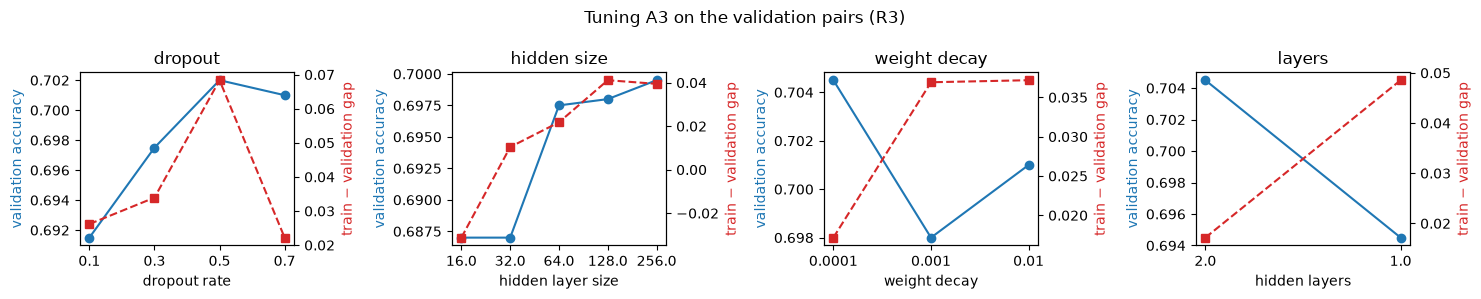

In [25]:
# one plot per step: validation accuracy (left axis) and gap (right axis)
steps = [("dropout", "dropout rate"), ("hidden size", "hidden layer size"), ("weight decay", "weight decay"), ("layers", "hidden layers")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (step, xlabel) in zip(axes, steps):
    part = tuning[tuning["step"] == step]
    positions = range(len(part))
    ax.plot(positions, part["val acc"], marker="o", color="tab:blue", label="validation accuracy")
    ax.set_xticks(list(positions))
    ax.set_xticklabels([str(v) for v in part["value"]])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("validation accuracy", color="tab:blue")
    gap_axis = ax.twinx()
    gap_axis.plot(positions, part["gap"], marker="s", linestyle="--", color="tab:red", label="gap")
    gap_axis.set_ylabel("train − validation gap", color="tab:red")
    ax.set_title(step)
plt.suptitle("Tuning A3 on the validation pairs (R3)")
plt.tight_layout()
plt.savefig("results/graphs/a3_tuning.png", dpi=150)
plt.show()

**A3** = the MLP with the number of hidden layers, dropout, hidden size and weight decay found above. It trains for 15 epochs; the course code keeps the epoch with the lowest validation loss, so later overfitting does not change the model that is evaluated.

In [26]:
A3 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": best_hidden, "dropout": float(best_dropout), "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": float(best_weight_decay), "num_epochs": 15},
    "num_layers": best_layers,
}
print("A3:", A3["num_layers"], "hidden layer(s),", A3["smlp_args"])

A3: 2 hidden layer(s), {'hidden_dim': 256, 'dropout': 0.5, 'batch_size': 64, 'learning_rate': 0.0001, 'weight_decay': 0.0001, 'num_epochs': 15}


In [27]:
run("A3_R1", R1, A3)
run("A3_R2", R2, A3)
run("A3_R3", R3, A3)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.987 seconds
Dataloader done! Time taken: 0.587 seconds
Training...


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0882 | train acc: 0.3923 | val loss: 1.0588 | val acc: 0.4901
Epoch 02 | train loss: 1.0144 | train acc: 0.4987 | val loss: 0.9698 | val acc: 0.5422
Epoch 03 | train loss: 0.9403 | train acc: 0.5589 | val loss: 0.9299 | val acc: 0.5662
Epoch 04 | train loss: 0.8928 | train acc: 0.5940 | val loss: 0.9094 | val acc: 0.5756
Epoch 05 | train loss: 0.8529 | train acc: 0.6151 | val loss: 0.8999 | val acc: 0.5783
Epoch 06 | train loss: 0.8230 | train acc: 0.6351 | val loss: 0.8946 | val acc: 0.5832
Epoch 07 | train loss: 0.7931 | train acc: 0.6537 | val loss: 0.8913 | val acc: 0.5895
Epoch 08 | train loss: 0.7628 | train acc: 0.6729 | val loss: 0.8936 | val acc: 0.5926
Epoch 09 | train loss: 0.7365 | train acc: 0.6860 | val loss: 0.8930 | val acc: 0.5927
Epoch 10 | train loss: 0.7096 | train acc: 0.6979 | val loss: 0.8934 | val acc: 0.5975
Epoch 11 | train loss: 0.6799 | train acc: 0.7189 | val loss: 0.8998 | val acc: 0.5991
Epoch 12 | train loss: 0.6507 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0879 | train acc: 0.3898 | val loss: 1.0543 | val acc: 0.4897
Epoch 02 | train loss: 1.0082 | train acc: 0.5068 | val loss: 0.9709 | val acc: 0.5368
Epoch 03 | train loss: 0.9318 | train acc: 0.5642 | val loss: 0.9366 | val acc: 0.5575
Epoch 04 | train loss: 0.8866 | train acc: 0.5969 | val loss: 0.9217 | val acc: 0.5684
Epoch 05 | train loss: 0.8498 | train acc: 0.6166 | val loss: 0.9126 | val acc: 0.5744
Epoch 06 | train loss: 0.8195 | train acc: 0.6355 | val loss: 0.9088 | val acc: 0.5775
Epoch 07 | train loss: 0.7888 | train acc: 0.6547 | val loss: 0.9075 | val acc: 0.5817
Epoch 08 | train loss: 0.7615 | train acc: 0.6708 | val loss: 0.9068 | val acc: 0.5821
Epoch 09 | train loss: 0.7349 | train acc: 0.6839 | val loss: 0.9108 | val acc: 0.5894
Epoch 10 | train loss: 0.7034 | train acc: 0.7026 | val loss: 0.9139 | val acc: 0.5890
Epoch 11 | train loss: 0.6739 | train acc: 0.7180 | val loss: 0.9175 | val acc: 0.5882
Epoch 12 | train loss: 0.6414 | train acc: 

... (26 outputs left out)

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0470 | train acc: 0.4577 | val loss: 0.9271 | val acc: 0.5961
Epoch 02 | train loss: 0.8735 | train acc: 0.6040 | val loss: 0.8047 | val acc: 0.6519
Epoch 03 | train loss: 0.7882 | train acc: 0.6594 | val loss: 0.7730 | val acc: 0.6653
Epoch 04 | train loss: 0.7420 | train acc: 0.6824 | val loss: 0.7600 | val acc: 0.6720
Epoch 05 | train loss: 0.7071 | train acc: 0.7032 | val loss: 0.7542 | val acc: 0.6722
Epoch 06 | train loss: 0.6708 | train acc: 0.7204 | val loss: 0.7541 | val acc: 0.6748
Epoch 07 | train loss: 0.6413 | train acc: 0.7351 | val loss: 0.7528 | val acc: 0.6757
Epoch 08 | train loss: 0.6109 | train acc: 0.7483 | val loss: 0.7574 | val acc: 0.6814
Epoch 09 | train loss: 0.5781 | train acc: 0.7657 | val loss: 0.7586 | val acc: 0.6800
Epoch 10 | train loss: 0.5417 | train acc: 0.7849 | val loss: 0.7663 | val acc: 0.6833
Epoch 11 | train loss: 0.5109 | train acc: 0.7990 | val loss: 0.7805 | val acc: 0.6822
Epoch 12 | train loss: 0.4758 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0507 | train acc: 0.4497 | val loss: 0.9319 | val acc: 0.5836
Epoch 02 | train loss: 0.8781 | train acc: 0.6065 | val loss: 0.8132 | val acc: 0.6420
Epoch 03 | train loss: 0.7870 | train acc: 0.6603 | val loss: 0.7864 | val acc: 0.6527
Epoch 04 | train loss: 0.7394 | train acc: 0.6832 | val loss: 0.7750 | val acc: 0.6617
Epoch 05 | train loss: 0.7060 | train acc: 0.7037 | val loss: 0.7687 | val acc: 0.6663
Epoch 06 | train loss: 0.6758 | train acc: 0.7190 | val loss: 0.7662 | val acc: 0.6679
Epoch 07 | train loss: 0.6439 | train acc: 0.7341 | val loss: 0.7679 | val acc: 0.6695
Epoch 08 | train loss: 0.6138 | train acc: 0.7501 | val loss: 0.7678 | val acc: 0.6684
Epoch 09 | train loss: 0.5762 | train acc: 0.7701 | val loss: 0.7773 | val acc: 0.6692
Epoch 10 | train loss: 0.5453 | train acc: 0.7825 | val loss: 0.7841 | val acc: 0.6712
Epoch 11 | train loss: 0.5113 | train acc: 0.7980 | val loss: 0.7940 | val acc: 0.6709
Epoch 12 | train loss: 0.4780 | train acc: 

## 7. Results

### 7a. Accuracy of all nine systems

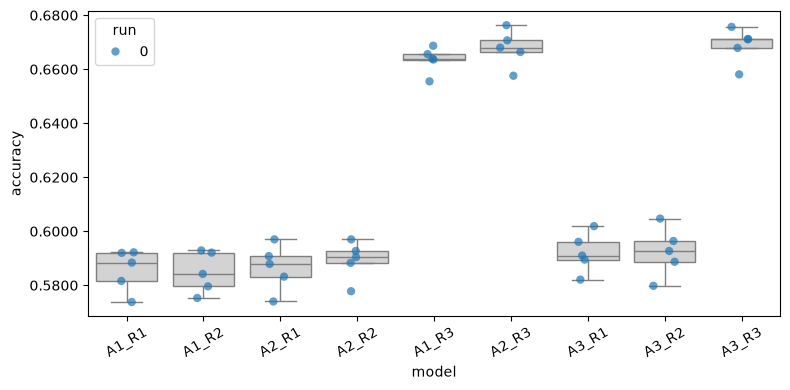

,R1,R2,R3
A1,0.5856,0.5848,0.6635
A2,0.5866,0.5892,0.6678
A3,0.5921,0.5925,0.6688


In [28]:
df_results = part1.analysis.make_data_frame(my_classifiers)
part1.analysis.plot_box_and_points(df_results)

# table: mean accuracy for every architecture (rows) and representation (columns)
table = pd.DataFrame(index=["A1", "A2", "A3"], columns=["R1", "R2", "R3"], dtype=float)
for a in ["A1", "A2", "A3"]:
    for r in ["R1", "R2", "R3"]:
        name = a + "_" + r
        table.loc[a, r] = df_results[df_results["model"] == name]["accuracy"].mean()
table.round(4)

### 7b. Per-class F1 (other aspects of performance)

Accuracy is one number for all three labels together. **Per-class F1** shows whether every label works, or whether one label is much harder. We compute it from the cross-validation predictions (each fold's model on its own validation part) and average over the folds. **Macro-F1** is the average over the three labels; because the classes are balanced, it should rank the systems the same way as accuracy.

,entailment,neutral,contradiction,macro-F1,accuracy
system,,,,,
A1_R1,0.621,0.564,0.569,0.585,0.586
A1_R2,0.621,0.562,0.568,0.584,0.585
A2_R1,0.619,0.567,0.572,0.586,0.587
A2_R2,0.622,0.571,0.572,0.588,0.589
A1_R3,0.721,0.600,0.663,0.661,0.663
A2_R3,0.725,0.612,0.662,0.666,0.668
A3_R1,0.627,0.574,0.573,0.591,0.592
A3_R2,0.629,0.574,0.571,0.591,0.592
A3_R3,0.725,0.612,0.665,0.667,0.669


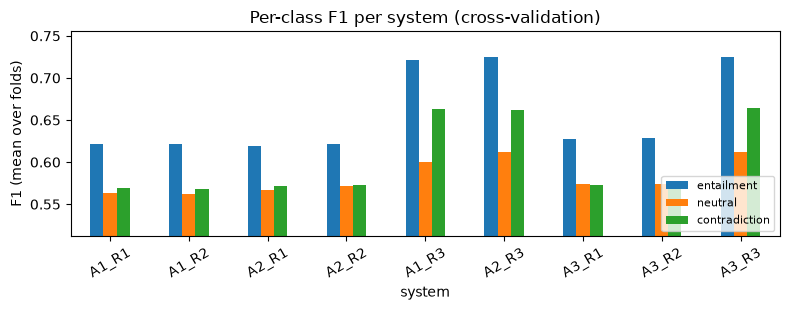

In [29]:
rows = []
for name in my_classifiers:
    per_fold = []
    for seed_index, seed in enumerate(my_seeds):
        result = my_classifiers[name][seed_index]
        for fold, predictions in result["predictions"].items():
            gold = []
            for pair, label in cv_sets[seed][fold]["validation"]:
                gold.append(label)
            per_fold.append(f1_score(gold, predictions, average=None, labels=[0, 1, 2]))
    per_class = np.mean(per_fold, axis=0)
    rows.append({"system": name, "entailment": per_class[0], "neutral": per_class[1],
                 "contradiction": per_class[2], "macro-F1": per_class.mean(),
                 "accuracy": accuracies_of(my_classifiers[name]).mean()})
f1_table = pd.DataFrame(rows).set_index("system")
display(f1_table.round(3))

f1_table[["entailment", "neutral", "contradiction"]].plot.bar(rot=30, figsize=(8, 3.2))
plt.ylim(f1_table[["entailment", "neutral", "contradiction"]].values.min() - 0.05, f1_table[["entailment", "neutral", "contradiction"]].values.max() + 0.03)
plt.ylabel("F1 (mean over folds)")
plt.title("Per-class F1 per system (cross-validation)")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("results/graphs/per_class_f1.png", dpi=150)
plt.show()

### 7c. Bayesian analysis

**ROPE (region of practical equivalence).** Following the tutorial, the ROPE is the smallest accuracy difference we consider *worth the effort*. We use **0.01**: for a bag-of-words NLI classifier, a gain below one percentage point does not justify a bigger or slower model. It also matches the noise level: accuracy measured on the ~10k test pairs has a standard error of about 0.005, so smaller differences are within the noise of the measurement itself. For comparison we also report the tutorial's ROPE of 0.005.

In [30]:
acc = df_results["accuracy"].mean()
n = len(test_pairs)
standard_error = np.sqrt(acc * (1 - acc) / n)
print("standard error on the test set (n =", n, "):", round(standard_error, 4))

ROPE = 0.01

standard error on the test set (n = 9824 ): 0.0049


**Comparisons, one factor at a time.** For each pair of systems A and B, `BenavoliCorrelatedT` gives a distribution over the mean accuracy difference (B − A), taking into account that cross-validation folds overlap. We report the probability that A is better, that they are practically equivalent (difference inside the ROPE), and that B is better.

1. **Representations** (architecture fixed to A1): R1 vs R2, R2 vs R3
2. **Architectures** (representation fixed to the best one from step 1): A1 vs A2, A2 vs A3
3. **Best system vs. the tutorial default** (A1_R1)

best representation with A1: R3 | highest mean accuracy: A3_R3


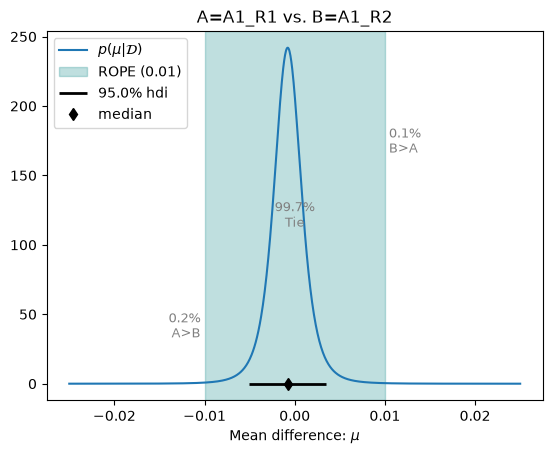

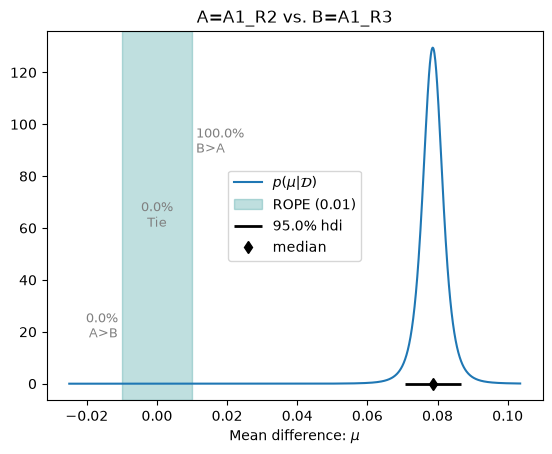

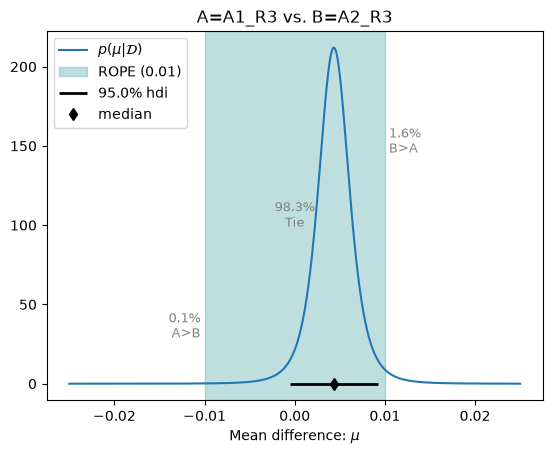

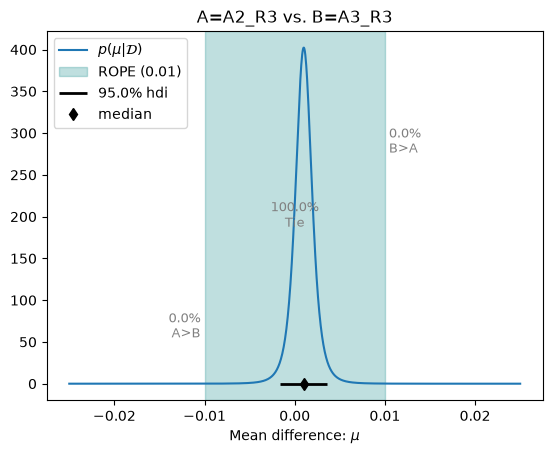

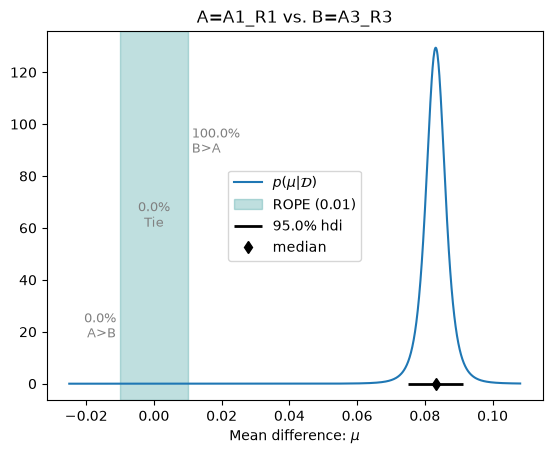

,A,B,mean diff (B-A),effect size,P(A better) 0.005,P(equivalent) 0.005,P(B better) 0.005,P(A better) 0.01,P(equivalent) 0.01,P(B better) 0.01
0,A1_R1,A1_R2,-0.001,-0.503,0.026,0.963,0.010,0.002,0.997,0.001
1,A1_R2,A1_R3,0.079,27.165,0.000,0.000,1.000,0.000,0.000,1.000
2,A1_R3,A2_R3,0.004,2.453,0.003,0.633,0.364,0.001,0.983,0.016
3,A2_R3,A3_R3,0.001,1.073,0.001,0.992,0.006,0.000,1.000,0.000
4,A1_R1,A3_R3,0.083,28.720,0.000,0.000,1.000,0.000,0.000,1.000


In [31]:
def get_accuracies(name):
    return accuracies_of(my_classifiers[name])


def compare(a, b, plot=True):
    acc_a = get_accuracies(a)
    acc_b = get_accuracies(b)

    # if the accuracies are exactly the same on every fold there is nothing to compare
    if np.allclose(acc_a, acc_b):
        print(a, "and", b, "have identical accuracies on every fold -> practically equivalent")
        row = {"A": a, "B": b, "mean diff (B-A)": 0.0, "effect size": 0.0}
        for rope in [0.005, ROPE]:
            row["P(A better) " + str(rope)] = 0.0
            row["P(equivalent) " + str(rope)] = 1.0
            row["P(B better) " + str(rope)] = 0.0
        return row

    posterior = part1.analysis.BenavoliCorrelatedT(acc_a, acc_b, runs=len(my_seeds), names=[a, b])
    row = {"A": a, "B": b, "mean diff (B-A)": posterior.mean_diff, "effect size": posterior.effect_size}

    for rope in [0.005, ROPE]:
        p_a, p_tie, p_b = posterior.probs(rope)
        row["P(A better) " + str(rope)] = p_a
        row["P(equivalent) " + str(rope)] = p_tie
        row["P(B better) " + str(rope)] = p_b

    if plot:
        posterior.plot(ROPE)
        plt.savefig("results/graphs/posterior_" + a + "_vs_" + b + ".png", dpi=150, bbox_inches="tight")
        plt.show()
    return row


# best representation when the architecture is A1
best_rep = "R1"
for r in ["R2", "R3"]:
    if get_accuracies("A1_" + r).mean() > get_accuracies("A1_" + best_rep).mean():
        best_rep = r

# best system overall (highest mean CV accuracy)
best_system = None
for name in my_classifiers:
    if best_system is None or get_accuracies(name).mean() > get_accuracies(best_system).mean():
        best_system = name

print("best representation with A1:", best_rep, "| highest mean accuracy:", best_system)

pairs_to_compare = [
    ("A1_R1", "A1_R2"),
    ("A1_R2", "A1_R3"),
    ("A1_" + best_rep, "A2_" + best_rep),
    ("A2_" + best_rep, "A3_" + best_rep),
]
if best_system != "A1_R1":
    pairs_to_compare.append(("A1_R1", best_system))

rows = []
for a, b in pairs_to_compare:
    rows.append(compare(a, b))
comparison = pd.DataFrame(rows)
comparison.round(3)

### 7d. Choosing the best system

**Rule:** we take the system with the highest mean CV accuracy, **unless a simpler system is practically equivalent to it** (P(equivalent) ≥ 0.95 with ROPE 0.01). In that case we prefer the simpler one: it is faster to train and easier to inspect, and the extra complexity buys no accuracy that matters. Simpler means: A1 before A2 before A3, and R1/R2 before R3 (fewer dimensions).

In [32]:
# order from simplest to most complex
simplicity_order = ["A1_R1", "A1_R2", "A1_R3", "A2_R1", "A2_R2", "A2_R3", "A3_R1", "A3_R2", "A3_R3"]

chosen = best_system
for name in simplicity_order:
    if name == best_system:
        break   # nothing simpler is equivalent
    row = compare(name, best_system, plot=False)
    if row.get("P(equivalent) " + str(ROPE), 0) >= 0.95:
        chosen = name
        print(name, "is practically equivalent to", best_system, "-> we choose the simpler", name)
        break

print("highest accuracy:", best_system, round(get_accuracies(best_system).mean(), 4))
print("chosen system:   ", chosen, round(get_accuracies(chosen).mean(), 4))

A1_R3 is practically equivalent to A3_R3 -> we choose the simpler A1_R3
highest accuracy: A3_R3 0.6688
chosen system:    A1_R3 0.6635


## 8. Test set (once)

Finally we train the chosen system on all 50,000 training pairs and evaluate it **once** on SNLI's test set. We report accuracy, macro-F1, per-class scores and the confusion matrix, which shows which labels get confused with each other.

A1_R3 on the test set: accuracy 0.6752 | macro-F1 0.6726
               precision    recall  f1-score   support

   entailment       0.71      0.77      0.74      3368
      neutral       0.64      0.59      0.62      3219
contradiction       0.67      0.66      0.66      3237

     accuracy                           0.68      9824
    macro avg       0.67      0.67      0.67      9824
 weighted avg       0.67      0.68      0.67      9824



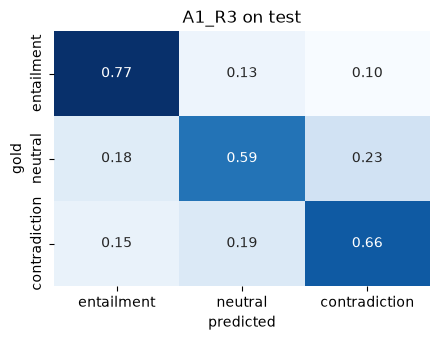

In [33]:
final = chosen
architecture_name = final.split("_")[0]
representation_name = final.split("_")[1]

if representation_name == "R1":
    encoder = R1
elif representation_name == "R2":
    encoder = R2
else:
    encoder = R3

if architecture_name == "A1":
    architecture = A1
elif architecture_name == "A2":
    architecture = A2
else:
    architecture = A3

test_texts = []
gold = []
for pair, label in test_pairs:
    test_texts.append(pair)
    gold.append(label)

if architecture["model_option"] == "logistic":
    model = part1.loglin.fit(train_pairs, encoder, max_iter=architecture["loglin_args"]["max_iter"])
    preds = part1.loglin.predict(test_texts, model, encoder)
else:
    # val_pairs is only used to pick the best epoch, the test set is only used for predicting
    use_layers(architecture["num_layers"])
    settings = architecture["smlp_args"]
    part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), encoder, save_to="results/final_model",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    model = part1.smlp.load("results/final_model")
    probabilities = part1.smlp.predict_probs(test_texts, model, encoder, batch_size=256)
    preds = probabilities.argmax(axis=1)   # the label with the highest probability

print(final, "on the test set: accuracy", round(accuracy_score(gold, preds), 4),
      "| macro-F1", round(f1_score(gold, preds, average="macro"), 4))
print(classification_report(gold, preds, target_names=list(LABELS)))

cm = confusion_matrix(gold, preds, normalize="true")
plt.figure(figsize=(4.5, 3.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=list(LABELS), yticklabels=list(LABELS))
plt.xlabel("predicted")
plt.ylabel("gold")
plt.title(final + " on test")
plt.tight_layout()
plt.savefig("results/graphs/confusion_matrix_test.png", dpi=150)
plt.show()

## Conclusions

**Data**
- Labels are balanced in every split (about 1/3 each; majority baseline 0.336), so **accuracy is a fair metric**. Only 785 / 158 / 176 pairs (train / validation / test) were removed for having no agreed label.

**Tokenizer**
- At vocab size 1000, training on our sample gives 16.39 tokens per sentence and training on all SNLI text gives 16.50. News text gives 22.64. So SNLI-specific text matters, but the amount of extra SNLI text does not (the two SNLI tokenizers are almost the same). The UNK rate is close to 0 for all of them.
- Vocabulary 1000 vs 2000 (A2_R2, CV accuracy 0.5892 vs 0.5929): P(equivalent) = 0.916 and P(2000 better) = 0.074, so we keep 1000 (half the dimensions). Vocab 500 (0.5759) and the news tokenizer (0.5787) are lower, and vocab 4000 (0.5896) does not improve on 2000.

**Representations** (ROPE 0.01)
- R1 vs R2 (A1): mean difference −0.001, P(equivalent) = 0.997, so they are practically equivalent. This is expected because tokens rarely occur twice in short sentences.
- R2 vs R3 (A1): mean difference +0.079 (0.5848 → 0.6635), P(R3 better) = 1.000. The feature table (5b) shows why. Overlap is higher for entailment (0.525) than for neutral (0.368) and contradiction (0.331). Entailment has fewer new tokens in H (4.3) than neutral (7.9) and contradiction (7.2). Length difference is most negative for entailment (−0.329, vs −0.188 neutral and −0.259 contradiction). The negation flag is set about 6× as often for contradiction (0.049) as for entailment and neutral (0.008).

**Architectures**
- A1 and A2 overfit only a little on R3. The train vs validation gap is 0.034 for A1 (0.722 vs 0.688) and 0.035 for A2 (0.725 vs 0.690).
- A3 (second hidden layer, tuned on the validation pairs) uses dropout 0.5, hidden size 256 and weight decay 1e-4 (validation accuracy 0.7045, gap 0.017). In the 2 vs 1 layer check, the second layer gets 0.7045 against 0.6945 for one layer, so A3 uses 2 hidden layers.
- A1 vs A2 (R3): mean difference +0.004, P(equivalent) = 0.983. A2 vs A3 (R3): mean difference +0.001, P(equivalent) = 1.000. Both pairs are practically equivalent. Changing the architecture gains much less than changing the representation.

**Evaluation**
- Per-class F1: neutral is the hardest label for every system (0.562–0.612). Macro-F1 ranks the systems the same as accuracy (balanced classes).

**Best system**
- Highest CV accuracy: A3_R3 (0.6688). Chosen system (the simplest one that is practically equivalent): A1_R3 (0.6635; P(equivalent) with A3_R3 ≥ 0.95 at ROPE 0.01). On the test set it gets accuracy 0.6752 and macro-F1 0.6726.
- Confusion matrix (row-normalised): entailment has the highest recall (0.77) and neutral the lowest (0.59). The most common error is neutral predicted as contradiction (0.23). Contradiction is mostly confused with neutral (0.19) and less with entailment (0.15).

**Limitations**
- 50k of ~550k training pairs, one random sample and one seed (5 measurements per system).
- Bag-of-words ignores word order ("man bites dog" = "dog bites man").
- The folds are split randomly by pair, so the same premise can appear in training and validation.
- For the MLPs, the course code reports each fold's accuracy at the epoch with the best loss on that same fold, which slightly favours the MLPs.
- A3 was tuned one setting at a time on 2,000 validation pairs, not with a full grid; the second hidden layer has the same size as the first.